## Statistics for Machine Learning - Practice Workbook

In [1]:
# Core imports used throughout the notebook
import numpy as np                      
import scipy.stats as st                # gmean, hmean, norm, binom distributions
from scipy import stats
import math                             # sqrt, comb

### ============================================================
### Part 1: Measures of Central Tendency (15 Questions)
### ============================================================

#### Q1. Arithmetic Mean:- The weekly sales (in units) of a retail store were: 48, 52, 61, 57, 49, 63, 70
> **Calculate**:
> 1. The arithmetic mean.
> 2. The deviation of each observation from the mean.
> 3. Verify that the sum of deviations from the mean is zero.

> **Note** -> According to the property of mean, the sum of deviations should always be zero.

In [2]:
# Store all weekly sales inside a NumPy array
sales = np.array([48, 52, 61, 57, 49, 63, 70])

# 1. Calculate the arithmetic mean (average)
mean = sales.mean()

# 2. Find the deviation of every observation
# Deviation = Observation - Mean
deviations = sales - mean

# Print the arithmetic mean
print("Arithmetic Mean =", mean)

# Print deviations
print("Deviation of each observation =")
print(deviations)

# 3. Verify that the sum of deviations from the mean 
# is zero.
print("Sum of deviations =", deviations.sum())

Arithmetic Mean = 57.142857142857146
Deviation of each observation =
[-9.14285714 -5.14285714  3.85714286 -0.14285714 -8.14285714  5.85714286
 12.85714286]
Sum of deviations = -2.1316282072803006e-14


#### Q2. Mean with Missing Observation:- The average of six numbers is 38. Five of the numbers are: 24, 35, 42, 40, 45. Find the missing number.

In [3]:
# Total observations(numbers)
n = 6

# Given mean
mean = 38

# Store the known numbers
known = np.array([24, 35, 42, 40, 45])

# Calculate total sum
total = n * mean

# Calculate missing number
missing = total - known.sum()

# Display result
print("Missing Number =", missing)

Missing Number = 42


#### Q3. Effect of a New Observation:- The mean of eight observations is 27. A ninth observation with value 45 is added. Find the new mean.

In [4]:
# Number of old observations
old_n = 8

# Old mean
old_mean = 27

# New observation
new_value = 45

# Calculate new mean
new_mean = (old_n * old_mean + new_value) / (old_n + 1)

print("New Mean =", new_mean)

New Mean = 29.0


#### Q4. Combined Mean:- The average marks of 35 students in Section A are 68. The average marks of 25 students in Section B are 74. Find the average marks of all 60 students together.

In [5]:
# Students and average of Section A
n1 = 35
m1 = 68

# Students and average of Section B
n2 = 25
m2 = 74

# Calculate combined mean
combined_mean = (n1 * m1 + n2 * m2) / (n1 + n2)

print("Combined Mean =", combined_mean)

Combined Mean = 70.5


#### Q5. Weighted Mean:- A student's final grade is computed as follows:
> - Assignments: 20% (score = 82)
> - Midterm: 30% (score = 76)
> - Final Exam: 50% (score = 88)

> Calculate the weighted mean.

In [7]:
# Scores obtained
scores = np.array([82, 76, 88])

# Weight of each score
weights = np.array([0.20, 0.30, 0.50])

# Calculate weighted mean
weighted_mean = np.sum(scores * weights) / np.sum(weights)

# Display result
print("Weighted Mean =", weighted_mean)

Weighted Mean = 83.2


#### Q6. Median (Odd Number of Observations):- The daily temperatures (C) are: 29, 31, 28, 35, 33, 30, 32. Find the median.

> **Note** -> The Median is the middle value of a dataset after arranging the data in ascending order.

In [8]:
# Store all temperatures in a NumPy array
temps = np.array([29, 31, 28, 35, 33, 30, 32])

# Sort the temperatures in ascending order
sorted_temps = np.sort(temps)

# Find the median:-
# Since there are 7 observations (odd),
# NumPy returns the middle value
median = np.median(temps)

# Display sorted data
print("Sorted Temperatures =", sorted_temps)

# Display median
print("Median =", median)

Sorted Temperatures = [28 29 30 31 32 33 35]
Median = 31.0


#### Q7. Median (Even Number of Observations):- The monthly expenses (₹) are: 2200, 2500, 1800, 3100, 2900, 2600, 2400, 2800. Find the median.

> **Note** -> If the number of observations is even, the median is the average of the two middle values after sorting.

In [9]:
# Store all expenses
expenses = np.array([2200, 2500, 1800, 3100, 2900, 2600, 2400, 2800])

# Sort expenses
sorted_expenses = np.sort(expenses)

# Calculate median
median = np.median(expenses)

# Display sorted expenses
print("Sorted Expenses =", sorted_expenses)

# Display median
print("Median =", median)

Sorted Expenses = [1800 2200 2400 2500 2600 2800 2900 3100]
Median = 2550.0


#### Q8. Mode:- Determine the mode of the following dataset: 12, 15, 18, 15, 20, 18, 15, 22, 18, 15. State whether the distribution is unimodal, bimodal, or multimodal.

> **Note** -> The Mode is the value that appears most frequently.
> - One mode → Unimodal
> - Two modes → Bimodal
> - More than two modes → Multimodal

In [10]:
# Import Counter to count frequencies
from collections import Counter

# Store data
data = [12, 15, 18, 15, 20, 18, 15, 22, 18, 15]

# Count frequency of each value
counts = Counter(data)

# Find highest frequency
max_frequency = max(counts.values())

# Find value(s) having highest frequency
modes = [value for value, frequency in counts.items()
         if frequency == max_frequency]

# Display frequencies
print("Frequencies =", counts)

# Display mode
print("Mode =", modes)

# Check type of distribution
if len(modes) == 1:
    print("Distribution = Unimodal")
elif len(modes) == 2:
    print("Distribution = Bimodal")
else:
    print("Distribution = Multimodal")

Frequencies = Counter({15: 4, 18: 3, 12: 1, 20: 1, 22: 1})
Mode = [15]
Distribution = Unimodal


#### Q9. Mean, Median and Mode:- For the following dataset: 15, 16, 18, 18, 19, 20, 20, 21, 24.
> **Calculate**:
> 1. Mean
> 2. Median
> 3. Mode

> Comment on the relationship among the three measures.

In [11]:
# Import SciPy statistics module
from scipy import stats

# Store data
data = np.array([15, 16, 18, 18, 19, 20, 20, 21, 24])

# Calculate mean
mean = data.mean()

# Calculate median
median = np.median(data)

# Find one mode using SciPy
mode = stats.mode(data, keepdims=True).mode[0]

# Display results
print("Mean =", mean)
print("Median =", median)
print("Mode returned by SciPy =", mode)

print("\nNote: 18 and 20 both occur twice, so the dataset is bimodal.")

Mean = 19.0
Median = 19.0
Mode returned by SciPy = 18

Note: 18 and 20 both occur twice, so the dataset is bimodal.


#### Q10. Effect of an Outlier:- Consider the dataset: 18, 20, 21, 22, 23, 24, 90
> **Calculate**:
> 1. Mean
> 2. Median

> Which measure better represents the central tendency? Give a reason.
>
> **Outlier** -> An Outlier is a value that is much larger or much smaller than the other observations.

> **Best Measure = Median**, because it is not heavily affected by outliers.

In [12]:
# Store data
data = np.array([18, 20, 21, 22, 23, 24, 90])

# Calculate mean
mean = data.mean()

# Calculate median
median = np.median(data)

# Display results
print("Mean =", round(mean, 2))
print("Median =", median)

# Explain the result
print("\n90 is an outlier.")
print("It increases the mean, but the median stays almost unchanged.")
print("Therefore, the median is a better measure of central tendency.")

Mean = 31.14
Median = 22.0

90 is an outlier.
It increases the mean, but the median stays almost unchanged.
Therefore, the median is a better measure of central tendency.


#### Q11. Geometric Mean:- The annual growth factors of a company's revenue over four years are: 1.08, 1.12, 0.96, 1.10. Calculate the geometric mean growth factor.

> **Note** -> gmean() multiplies all values and then takes the nth root.

In [13]:
# Import geometric mean function
from scipy import stats as st

# Store all growth factors
growth_factors = np.array([1.08, 1.12, 0.96, 1.10])

# Calculate Geometric Mean
gm = st.gmean(growth_factors)

# Display the result
print("Geometric Mean Growth Factor =", gm)

Geometric Mean Growth Factor = 1.063105644671346


#### Q12. Harmonic Mean:- 
> A car travels:
> - 60 km at 40 km/h
> - 60 km at 80 km/h

> Calculate the average speed using the harmonic mean.
>
> **Note** -> The Harmonic Mean is used when:
> - Distance is same
> - Speed is different

In [14]:
# Import Harmonic Mean function
from scipy import stats as st

# Store speeds
speeds = np.array([40, 80])

# Calculate Harmonic Mean
# Because equal distances are travelled
hm = st.hmean(speeds)

# Display result
print("Average Speed =", hm, "km/h")

Average Speed = 53.33333333333333 km/h


#### Q13. Grouped Data Mean:- The following frequency distribution gives the ages of employees.

| Age(Years) | Frequency |
|------------|-----------|
| 20-30 | 6 |
| 30-40 | 10 |
| 40-50 | 12 |
| 50-60 | 7 |
| 60-70 | 5 |

--- 
> Calculate the arithmetic mean

In [15]:
# Frequency (number of employees)
frequency = [6, 10, 12, 7, 5]

# Midpoints of each age group
midpoints = [25, 35, 45, 55, 65]

# Find total frequency (Σf)
total_frequency = sum(frequency)

# Multiply frequency with midpoint (f × x)
fx = []

for f, x in zip(frequency, midpoints):
    fx.append(f * x)

# Find Σ(fx)
total_fx = sum(fx)

# Mean = Σ(fx) / Σf
mean = total_fx / total_frequency

# Display results
print("Frequency =", frequency)
print("Midpoints =", midpoints)
print("f × x =", fx)
print("Σf =", total_frequency)
print("Σfx =", total_fx)
print("Arithmetic Mean =", mean)

Frequency = [6, 10, 12, 7, 5]
Midpoints = [25, 35, 45, 55, 65]
f × x = [150, 350, 540, 385, 325]
Σf = 40
Σfx = 1750
Arithmetic Mean = 43.75


#### Q14. Missing Frequency:- The mean of the following distribution is 24.

| Value | Frequency | 
|-------|-----------|
| 10 | 4 |
| 20 | 6 |
| 30 | x | 
| 40 | 5 |

---
> Find the value of x.

In [16]:
# Given values
mean = 24

# Known values
values = [10, 20, 40]
frequencies = [4, 6, 5]

# Calculate known totals
known_fx = sum(v * f for v, f in zip(values, frequencies))
known_f = sum(frequencies)

# Let missing frequency = x
# Equation:
# mean = (known_fx + 30*x) / (known_f + x)

# Rearranging:
# mean*(known_f + x) = known_fx + 30*x
# mean*known_f + mean*x = known_fx + 30*x
# (mean - 30)*x = known_fx - mean*known_f

x = (known_fx - mean * known_f) / (mean - 30)

print("Missing Frequency =", int(x))

Missing Frequency = 0


#### Q15. Comparative Study :- The average monthly income of employees in Company A is ₹58,000 and in Company B is ₹61,500. Company A has 180 employees and Company B has 120 employees. Find the overall average monthly income of all employees.

In [17]:
# Number of employees and mean income in Company A
n_A = 180
mean_A = 58000

# Number of employees and mean income in Company B
n_B = 120
mean_B = 61500

# Calculate the total income of both companies
total_income = (n_A * mean_A) + (n_B * mean_B)

# Calculate the total number of employees
total_employees = n_A + n_B

# Calculate the overall average income
overall_mean = total_income / total_employees

# Display the result
print("Overall Average Monthly Income = ₹", round(overall_mean, 2))

Overall Average Monthly Income = ₹ 59400.0


### ============================================================
### Part 2: Measures of Dispersion (15 Questions)
### ============================================================

#### Q16. Range:- The daily production (in units) of a factory over eight days is: 125, 138, 142, 119, 151, 136, 145, 132
> **Calculate**:
> 1. The range.
> 2. The coefficient of range.
>
> **Range** is the simplest measure of dispersion.
> It tells us the difference between the largest value and the smallest value.
> A larger range means more spread in the data.

> **Range = Maximum - Minimum**
> **Coefficient of range = Max - Min / Max + Min**

In [18]:
# Store daily production values
prod = np.array([125, 138, 142, 119, 151, 136, 145, 132])

# Find the maximum production
maximum = prod.max()

# Find the minimum production
minimum = prod.min()

# Calculate Range
range_value = maximum - minimum

# Calculate Coefficient of Range
coeff_range = range_value / (maximum + minimum)

# Display Maximum value
print("Maximum =", maximum)

# Display Minimum value
print("Minimum =", minimum)

# Display Range
print("Range =", range_value)

# Display Coefficient of Range
print("Coefficient of Range =", round(coeff_range,4))

Maximum = 151
Minimum = 119
Range = 32
Coefficient of Range = 0.1185


#### Q17. Quartiles and Interquartile Range:- The following are the test scores of 15 students: 42, 45, 48, 50, 53, 55, 57, 60, 62, 64, 66, 68, 70, 72, 75
> **Calculate**:
> 1. First Quartile (Q1)
> 2. Third Quartile (Q3)
> 3. Interquartile Range (IQR)
> 4. Quartile Deviation (Semi-IQR)

> 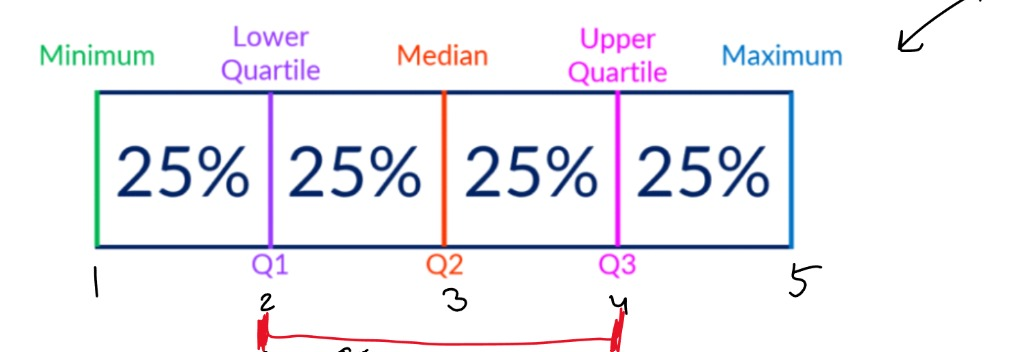

> **Note** -> Quartiles divide the data into 4 equal parts.
> - Q1 → 25% of data
> - Q2 → Median
> - Q3 → 75% of data

> The Interquartile Range (IQR) measures the spread of the middle 50% of the data.
> **IQR = Q3 - Q1**
> **Quartile Deviation = IQR / 2**

In [19]:
# Store students' scores
scores = np.array([42,45,48,50,53,55,57,60,62,64,66,68,70,72,75])

# Calculate First Quartile (25th percentile)
Q1 = np.percentile(scores,25)

# Calculate Third Quartile (75th percentile)
Q3 = np.percentile(scores,75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate Quartile Deviation
QD = IQR / 2

# IQR is less affected by outliers than Range.
# Display results
print("Q1 =",Q1)
print("Q3 =",Q3)
print("IQR =",IQR)
print("Quartile Deviation =",QD)

Q1 = 51.5
Q3 = 67.0
IQR = 15.5
Quartile Deviation = 7.75


#### Q18. Population Variance and Standard Deviation:- The number of defective items found during six inspections is: 3, 5, 4, 6, 7, 5

> **Calculate**:
> 1. Population mean
> 2. Population variance
> 3. Population standard deviation

> Variance tells us how far values are spread from the mean.

> Standard deviation is simply the square root of variance.

> Population Variance:-
> - σ2 = ∑(x−μ)^2 / N


In [20]:
# Store defects
defects = np.array([3,5,4,6,7,5])

# Calculate Population Mean
pop_mean = defects.mean()

# Calculate Population Variance
# ddof stands for Delta Degrees of Freedom
# ddof=0 means divide by N (Population)
pop_var = defects.var(ddof=0)

# Calculate Population Standard Deviation
pop_sd = defects.std(ddof=0)

# Display results
print("Population Mean =",pop_mean)

print("Population Variance =",pop_var)

print("Population Standard Deviation =",round(pop_sd,3))

Population Mean = 5.0
Population Variance = 1.6666666666666667
Population Standard Deviation = 1.291


#### Q19. Sample Variance and Standard Deviation:- The weights (kg) of a random sample of seven packages are: 18, 22, 21, 20, 19, 23, 17

> **Calculate**:
> 1. Sample mean
> 2. Sample variance
> 3. Sample standard deviation

In [21]:
# Store all package weights
weights = np.array([18, 22, 21, 20, 19, 23, 17])

# Calculate Sample Mean
sample_mean = weights.mean()

# Calculate Sample Variance
# ddof=1 means divide by (n-1)
# This is used because the data is a SAMPLE
sample_var = weights.var(ddof=1)

# Calculate Sample Standard Deviation
sample_sd = weights.std(ddof=1)

# Display results
print("Sample Mean =", sample_mean)
print("Sample Variance =", round(sample_var, 3))
print("Sample Standard Deviation =", round(sample_sd, 3))

Sample Mean = 20.0
Sample Variance = 4.667
Sample Standard Deviation = 2.16


#### Q20. Comparing Variability:- 

> Two machines produce bolts with the following lengths (mm):
> - Machine A: 48, 50, 49, 51, 52
> - Machine B: 42, 46, 50, 54, 58

> **Calculate**:
> 1. The mean for each machine.
> 2. The standard deviation for each machine.
> 3. Which machine produces more consistent bolt lengths?

> **Note** -> Standard Deviation (SD) measures how much data varies from the mean.
> - Smaller SD → More consistent
> - Larger SD → Less consistent

In [22]:
# Store Machine A data
A = np.array([48, 50, 49, 51, 52])

# Store Machine B data
B = np.array([42, 46, 50, 54, 58])

# Loop through both machines
for name, data in [("A", A), ("B", B)]:

    # Calculate Mean
    mean = data.mean()

    # Calculate Population Standard Deviation
    sd = data.std(ddof=0)

    # Display results
    print(f"Machine {name}")
    print("Mean =", mean)
    print("Standard Deviation =", round(sd, 3))
    print()

Machine A
Mean = 50.0
Standard Deviation = 1.414

Machine B
Mean = 50.0
Standard Deviation = 5.657



#### Q21. Coefficient of Variation:-

> Two investment portfolios have the following statistics:
> - Portfolio A: Mean return = 12%, Standard deviation = 2%
> - Portfolio B: Mean return = 18%, Standard deviation = 4%

> Calculate the coefficient of variation for each portfolio and determine which investment is more
consistent.

> When comparing two datasets with different means, use Coefficient of Variation, not just Standard Deviation.

In [23]:
# Store portfolio information
portfolios = {
    "A": (12, 2),   # Mean=12, Stad.dev.=2
    "B": (18, 4)    # Mean=18, Stad.dev.=4
}

# Loop through each portfolio
for name, (mean, sd) in portfolios.items():

    # Calculate Coefficient of Variation
    cv = (sd / mean) * 100

    # Display result
    print(f"Portfolio {name}")
    print("CV =", round(cv, 2), "%")

Portfolio A
CV = 16.67 %
Portfolio B
CV = 22.22 %


#### Q22. Effect of Adding a Constant:- The observations are: 14, 18, 22, 26, 30. Without recalculating from scratch, determine the new:
> 1. Mean
> 2. Variance
> 3. Standard deviation

> if 8 is added to every observation.

---
> Adding a constant shifts all values equally.
> - Mean changes
> - Variance does not change
> - Standard Deviation does not change

> Adding or subtracting a constant changes only the Mean. It does not affect the spread of the data.

In [24]:
# Store data
data = np.array([14, 18, 22, 26, 30])

# Calculate original statistics
mean = data.mean()
variance = data.var()
sd = data.std()

# Add 8 to the mean
new_mean = mean + 8

# Variance remains the same
new_variance = variance

# Standard deviation remains the same
new_sd = sd

# Display results
print("New Mean =", new_mean)
print("New Variance =", new_variance)
print("New Standard Deviation =", new_sd)

New Mean = 30.0
New Variance = 32.0
New Standard Deviation = 5.656854249492381


#### Q23. Effect of Multiplying by a Constant:- 
> The observations are: 5, 8, 11, 14, 17.

> Each observation is multiplied by 4.

> Determine the new:
> 1. Mean
> 2. Variance
> 3. Standard deviation

In [25]:
# Store observations
data = np.array([5, 8, 11, 14, 17])

# Calculate original statistics
mean = data.mean()
variance = data.var()
sd = data.std()

# Multiplication factor
k = 4

# Calculate new values
new_mean = mean * k
new_variance = variance * (k ** 2)
new_sd = sd * k

# Display results
print("New Mean =", new_mean)
print("New Variance =", new_variance)
print("New Standard Deviation =", new_sd)

New Mean = 44.0
New Variance = 288.0
New Standard Deviation = 16.97056274847714


#### Q24. Z-Score:- The marks obtained by students in an examination are normally distributed with:
> - Mean = 68
> - Standard deviation = 6

> Calculate the Z-score for a student who scored:
> - 74
> - 60
> - 68

> Interpret each result.

> **Note** -> A Z-score tells us how far a value is from the mean in terms of standard deviations.

> It helps compare scores from different datasets.

> Think of it like this:
> - Positive Z-score (+) → Above the mean
> - Negative Z-score (-) → Below the mean
> - Zero (0) → Exactly equal to the mean 

In [26]:
# Mean of the marks
mu = 68   # Store the mean

# Standard deviation of the marks
sigma = 6  

# List of student scores
scores = [74, 60, 68]

# Loop through each score
for score in scores:

    # Calculate Z-score using the formula
    z = (score - mu) / sigma

    # Display the result
    print(f"Score = {score}, Z-score = {z:.2f}")

Score = 74, Z-score = 1.00
Score = 60, Z-score = -1.33
Score = 68, Z-score = 0.00


#### Q25. Comparing Relative Consistency:- The monthly sales (in ₹ lakhs) of two companies are summarized below:
| Company | Mean | Standard Deviation | 
|---------|------|--------------------|
| A | 45 | 6 |
| B | 72 | 8 |  


> Using the coefficient of variation, determine which company has more stable monthly sales.
>
> **Formula**:-
> - **Coefficient of Variation(CV) = (Standard Deviation / Mean) * 100**
>
> - Where,
> - Mean (μ) = Average sales
> - Standard Deviation (σ) = Variation in sales
> - CV = Relative variability (in %)

> Rule: Lower CV = More Stable (More Consistent)

In [27]:
# Company A
mean_A = 45
std_A = 6

# Company B
mean_B = 72
std_B = 8

# Calculate CV using the formula:
# CV = (Standard Deviation / Mean) × 100
cv_A = (std_A / mean_A) * 100
cv_B = (std_B / mean_B) * 100

# Display the results
print("Company A CV =", round(cv_A, 2), "%")
print("Company B CV =", round(cv_B, 2), "%")

# Compare the CVs
if cv_A < cv_B:
    print("Company A has more stable monthly sales.")
elif cv_B < cv_A:
    print("Company B has more stable monthly sales.")
else:
    print("Both companies are equally stable.")

Company A CV = 13.33 %
Company B CV = 11.11 %
Company B has more stable monthly sales.


#### Q26. Variance from a Frequency Distribution:- The following data represent the number of customers visiting a store.
| Customer | Frequency |
|----------|-----------|
| 10 | 3 |
| 15 | 5 |
| 20 | 8 |
| 25 | 6 |
| 30 | 3 |

> **Calculate**:
> 1. Mean
> 2. Population variance
> 3. Population standard deviation

In [28]:
# Customer values (x)
x = np.array([10, 15, 20, 25, 30])

# Frequencies (f)
f = np.array([3, 5, 8, 6, 3])

# Total number of observations (N)
N = np.sum(f)

# ------------------------------
# Step 1: Calculate Mean
# Mean = Σ(f*x) / Σf
# ------------------------------
mean = np.sum(x * f) / N

# ------------------------------
# Step 2: Calculate Population Variance
# Variance = Σ[f*(x-mean)^2] / N
# ------------------------------
variance = np.sum(f * (x - mean) ** 2) / N

# ------------------------------
# Step 3: Calculate Population Standard Deviation
# SD = √Variance
# ------------------------------
std_dev = np.sqrt(variance)

# Display the results
print("Mean =", round(mean, 2))
print("Population Variance =", round(variance, 2))
print("Population Standard Deviation =", round(std_dev, 2))

Mean = 20.2
Population Variance = 34.96
Population Standard Deviation = 5.91


#### Q27. Detecting Outliers Using IQR:- The annual incomes (₹ thousands) of 12 employees are: 320, 340, 350, 360, 365, 370, 372, 375, 380, 385, 390, 520

> **Calculate**:
> 1. Q1
> 2. Q3
> 3. IQR
> 4. Lower and Upper Fences
> 5. Identify any outlier(s).

> The IQR (Interquartile Range) method helps identify values that are unusually low or high.

> **Rule**:-
> - Lower Fence = Q1 − 1.5 × IQR
> - Upper Fence = Q3 + 1.5 × IQR

> Any value:
> - Below the Lower Fence → Outlier
> - Above the Upper Fence → Outlier

In [29]:
# Store annual incomes
incomes = np.array([320,340,350,360,365,370,372,375,380,385,390,520])

# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1, Q3 = np.percentile(incomes, [25, 75])

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate Lower Fence
lower_fence = Q1 - 1.5 * IQR

# Calculate Upper Fence
upper_fence = Q3 + 1.5 * IQR

# Find all values outside the fences
outliers = incomes[(incomes < lower_fence) | (incomes > upper_fence)]

# Display results
print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Fence =", lower_fence)
print("Upper Fence =", upper_fence)
print("Outliers =", outliers)

Q1 = 357.5
Q3 = 381.25
IQR = 23.75
Lower Fence = 321.875
Upper Fence = 416.875
Outliers = [320 520]


#### Q28. Comparing Two Datasets:- 

> Dataset A: 25, 27, 28, 30, 31, 29, 30

> Dataset B: 18, 22, 26, 30, 34, 38, 42

> For each dataset, calculate:
> 1. Mean
> 2. Standard deviation

> Comment on which dataset is more dispersed.

In [30]:
# Create Dataset A
A = np.array([25, 27, 28, 30, 31, 29, 30])

# Create Dataset B
B = np.array([18, 22, 26, 30, 34, 38, 42])

# Calculate mean of Dataset A
mean_A = A.mean()

# Calculate population standard deviation of Dataset A
sd_A = A.std(ddof=0)

# Calculate mean of Dataset B
mean_B = B.mean()

# Calculate population standard deviation of Dataset B
sd_B = B.std(ddof=0)

# Display results
print("Dataset A")
print("Mean =", mean_A)
print("Standard Deviation =", sd_A)

print()

print("Dataset B")
print("Mean =", mean_B)
print("Standard Deviation =", sd_B)

print()

# Compare standard deviations
if sd_A > sd_B:
    print("Dataset A is more dispersed.")
else:
    print("Dataset B is more dispersed.")

Dataset A
Mean = 28.571428571428573
Standard Deviation = 1.9166296949998198

Dataset B
Mean = 30.0
Standard Deviation = 8.0

Dataset B is more dispersed.


#### Q29. Missing Observation:- The variance of the following population is 16. 
> 6, 8, 10, x, 14

> Find the value(s) of x.

In [34]:
!pip install sympy

In [33]:
# Import SymPy before using sp.symbols()
import sympy as sp

# Create variable x
x = sp.symbols('x')

# Store the data
data = [6, 8, 10, x, 14]

# Total number of observations
n = len(data)

# Calculate mean
mean = sum(data) / n

# Calculate population variance
variance = sum((value - mean)**2 for value in data) / n

# Solve the equation:
# variance = 16
answer = sp.solve(variance - 16, x)

# Display answer
print("Value of x =", answer)

Value of x = [2, 17]


#### Q30. Quality Control Application:- A quality engineer measures the diameters (mm) of ten machine parts: 20.1, 19.9, 20.0, 20.2, 19.8, 20.1, 20.0, 19.9, 20.2, 20.3

> **Calculate**:
> 1. Mean diameter
> 2. Sample standard deviation
> 3. Coefficient of variation

> Based on your calculations, comment on whether the manufacturing process appears to be consistent.

In [35]:
# Store the diameters
diameters = np.array([
    20.1, 19.9, 20.0, 20.2, 19.8,
    20.1, 20.0, 19.9, 20.2, 20.3
])

# Calculate mean
mean = diameters.mean()

# Calculate sample standard deviation
sample_sd = diameters.std(ddof=1)

# Calculate coefficient of variation
cv = (sample_sd / mean) * 100

# Display results
print("Mean =", mean)
print("Sample Standard Deviation =", sample_sd)
print("Coefficient of Variation =", cv, "%")

# Comment on consistency
if cv < 1:
    print("Manufacturing process is highly consistent.")
else:
    print("Manufacturing process shows noticeable variation.")

Mean = 20.05
Sample Standard Deviation = 0.15811388300841922
Coefficient of Variation = 0.7885979202414923 %
Manufacturing process is highly consistent.


### ============================================================
### Part 3: Probability (25 Questions)
### ============================================================

### Basic Probability 

#### Q31. Coin Toss:- A fair coin is tossed once. Find the probability of obtaining:
> 1. A Head.
> 2. A Tail.

In [36]:
# Probability of getting Head
p_head = 1 / 2

# Probability of getting Tail
p_tail = 1 / 2

# Display probabilities
print("Probability of Head =", p_head)
print("Probability of Tail =", p_tail)

Probability of Head = 0.5
Probability of Tail = 0.5


#### Q32. Two Coin Tosses:- Two fair coins are tossed simultaneously. Find the probability of obtaining:
> 1. Exactly one Head.
> 2. Two Heads.
> 3. At least one Head.

In [37]:
# Used to generate all possible outcomes
from itertools import product     

# Generate all outcomes of tossing 2 coins
outcomes = list(product(['H', 'T'], repeat=2))

# Total number of outcomes
total = len(outcomes)

# Count outcomes having exactly one Head
exactly_one_head = sum(1 for outcome in outcomes if outcome.count('H') == 1)

# Count outcomes having two Heads
two_heads = sum(1 for outcome in outcomes if outcome.count('H') == 2)

# Count outcomes having at least one Head
at_least_one_head = sum(1 for outcome in outcomes if outcome.count('H') >= 1)

# Calculate probabilities
print("Exactly One Head =", exactly_one_head / total)
print("Two Heads =", two_heads / total)
print("At Least One Head =", at_least_one_head / total)

Exactly One Head = 0.5
Two Heads = 0.25
At Least One Head = 0.75


#### Q33. Three Coin Tosses:- Three fair coins are tossed. Find the probability of obtaining:
> 1. Exactly two Heads.
> 2. At most one Head.
> 3. No Heads.

In [38]:
from itertools import product

# Generate all possible outcomes of 3 coin tosses
outcomes = list(product(['H', 'T'], repeat=3))

# Total outcomes
total = len(outcomes)

# Exactly two Heads
exactly_two_heads = sum(1 for outcome in outcomes if outcome.count('H') == 2)

# At most one Head (0 or 1 Head)
at_most_one_head = sum(1 for outcome in outcomes if outcome.count('H') <= 1)

# No Heads
no_heads = sum(1 for outcome in outcomes if outcome.count('H') == 0)

# Print probabilities
print("Exactly Two Heads =", exactly_two_heads / total)
print("At Most One Head =", at_most_one_head / total)
print("No Heads =", no_heads / total)

Exactly Two Heads = 0.375
At Most One Head = 0.5
No Heads = 0.125


#### Q34. Rolling a Die:- A fair die is rolled once. Find the probability of obtaining:
> 1. An even number.
> 2. A number greater than 4.
> 3. A prime number.

In [39]:
# Total outcomes on a die
total = 6

# Even numbers
even = [2, 4, 6]

# Numbers greater than 4
greater_than_4 = [5, 6]

# Prime numbers
prime = [2, 3, 5]

# Calculate probabilities
print("Even Number =", len(even) / total)
print("Greater Than 4 =", len(greater_than_4) / total)
print("Prime Number =", len(prime) / total)

Even Number = 0.5
Greater Than 4 = 0.3333333333333333
Prime Number = 0.5


#### Q35. Two Dice:- Two fair dice are rolled simultaneously. Find the probability that:
> 1. The sum is 7.
> 2. The sum is greater than 9.
> 3. Both dice show the same number.

In [40]:
from itertools import product

# Generate all possible outcomes of rolling 2 dice
pairs = list(product(range(1, 7), repeat=2))

# Total outcomes
total = len(pairs)

# Count pairs whose sum is 7
sum_7 = sum(1 for a, b in pairs if a + b == 7)

# Count pairs whose sum is greater than 9
sum_greater_9 = sum(1 for a, b in pairs if a + b > 9)

# Count pairs where both dice show the same number
same_number = sum(1 for a, b in pairs if a == b)

# Print probabilities
print("Sum = 7 :", sum_7 / total)
print("Sum > 9 :", sum_greater_9 / total)
print("Same Number :", same_number / total)

Sum = 7 : 0.16666666666666666
Sum > 9 : 0.16666666666666666
Same Number : 0.16666666666666666


### Cards

#### Q36. A card is drawn from a standard deck of 52 cards. Find the probability that it is:
> 1. An Ace.
> 2. A King.
> 3. A red card.
> 4. A face card.

In [41]:
# Total number of cards
total_cards = 52

# Number of each type of card
aces = 4
kings = 4
red_cards = 26
face_cards = 12

# Calculate probabilities
print("Ace =", aces / total_cards)
print("King =", kings / total_cards)
print("Red Card =", red_cards / total_cards)
print("Face Card =", face_cards / total_cards)

Ace = 0.07692307692307693
King = 0.07692307692307693
Red Card = 0.5
Face Card = 0.23076923076923078


#### Q37. Two cards are drawn one after another without replacement. Find the probability that:
> 1. Both are Aces.
> 2. Both are Kings.
> 3. The first card is a Queen and the second is a Jack.

In [42]:
# Probability of drawing two Aces
both_aces = (4 / 52) * (3 / 51)

# Probability of drawing two Kings
both_kings = (4 / 52) * (3 / 51)

# Probability of drawing Queen first, then Jack
queen_then_jack = (4 / 52) * (4 / 51)

# Print results
print("Both Aces =", both_aces)
print("Both Kings =", both_kings)
print("Queen then Jack =", queen_then_jack)

Both Aces = 0.004524886877828055
Both Kings = 0.004524886877828055
Queen then Jack = 0.006033182503770739


#### Q38. A card is drawn from a shuffled deck. Find the probability that the card is:
> 1. A red King.
> 2. A black Queen.
> 3. A card that is neither a face card nor an Ace.

In [43]:
# Total cards
total_cards = 52

# Number of Red Kings
red_kings = 2

# Number of Black Queens
black_queens = 2

# Cards that are face cards or Aces
face_or_ace = 12 + 4

# Cards that are neither face cards nor Ace
neither = total_cards - face_or_ace

# Calculate probabilities
print("Red King =", red_kings / total_cards)
print("Black Queen =", black_queens / total_cards)
print("Neither Face Card nor Ace =", neither / total_cards)

Red King = 0.038461538461538464
Black Queen = 0.038461538461538464
Neither Face Card nor Ace = 0.6923076923076923


### Urn Problems:-

#### Q39. A box contains:
> - 6 Red balls
> - 5 Blue balls
> - 4 Green balls

> Two balls are drawn without replacement. Find the probability that:
> 1. Both are Red.
> 2. One is Red and the other is Blue.
> 3. At least one is Green.

In [44]:
# Number of balls
red = 6
blue = 5
green = 4

# Total balls
total = red + blue + green

# 1. Probability that both balls are Red
both_red = (red / total) * ((red - 1) / (total - 1))

# 2. Probability of one Red and one Blue
red_then_blue = (red / total) * (blue / (total - 1))
blue_then_red = (blue / total) * (red / (total - 1))

one_red_one_blue = red_then_blue + blue_then_red

# 3. Probability of at least one Green
# First calculate probability of NO Green
no_green = ((red + blue) / total) * ((red + blue - 1) / (total - 1))

# Use complement rule
at_least_one_green = 1 - no_green

# Print answers
print("Both Red =", both_red)
print("One Red and One Blue =", one_red_one_blue)
print("At Least One Green =", at_least_one_green)

Both Red = 0.14285714285714288
One Red and One Blue = 0.2857142857142857
At Least One Green = 0.47619047619047616


#### Q40. A bag contains: 8 white balls and 7 black balls. Three balls are selected without replacement. Find the probability that:
> 1. All are white.
> 2. Exactly two are black.
> 3. None is black.

In [46]:
from math import comb

# Number of balls
white = 8
black = 7

# Total balls
total = white + black

# Balls selected
selected = 3

# 1. Probability that all are White
all_white = comb(white, 3) / comb(total, selected)

# 2. Probability of exactly two Black
two_black = (comb(black, 2) * comb(white, 1)) / comb(total, selected)

# 3. Probability that none is Black
none_black = comb(white, 3) / comb(total, selected)

# Print answers
print("All White =", all_white)
print("Exactly Two Black =", two_black)
print("None Black =", none_black)

All White = 0.12307692307692308
Exactly Two Black = 0.36923076923076925
None Black = 0.12307692307692308


### Conditional Probability:- 

#### Q41. A factory has three machines:
> - Machine A produces 40% of the items.
> - Machine B produces 35%.
> - Machine C produces 25%.

> The defective rates are:
> - A=2%
> - B=3%
> - C=5%

> If an item is selected at random, find the probability that it is defective.

In [47]:
# Probability that an item comes from each machine
machine_A = 0.40
machine_B = 0.35
machine_C = 0.25

# Defective rate of each machine
defect_A = 0.02
defect_B = 0.03
defect_C = 0.05

# Total probability of getting a defective item
probability_defective = (
    machine_A * defect_A +
    machine_B * defect_B +
    machine_C * defect_C
)

# Print answer
print("Probability of Defective Item =", probability_defective)

Probability of Defective Item = 0.031


#### Q42. A factory has three machines:
> - Machine A produces 40% of the items.
> - Machine B produces 35%.
> - Machine C produces 25%.

> The defective rates are:
> - A=2%
> - B=3%
> - C=5%

> suppose a randomly selected item is found to be defective. Find the probability that it was produced by Machine C.

In [48]:
# ==============================
# Bayes' Theorem
# ==============================

# Probability that an item is produced by each machine
P_A = 0.40
P_B = 0.35
P_C = 0.25

# Probability that an item is defective
# given it was produced by each machine
P_D_given_A = 0.02
P_D_given_B = 0.03
P_D_given_C = 0.05

# ---------------------------------
# Step 1: Total probability of a defective item
# P(D)
# ---------------------------------
P_D = (
    P_A * P_D_given_A +
    P_B * P_D_given_B +
    P_C * P_D_given_C
)

# ---------------------------------
# Step 2: Bayes' Theorem
# P(C|D)
# ---------------------------------
P_C_given_D = (P_C * P_D_given_C) / P_D

# Display the result
print("Probability that the defective item came from Machine C =",
      round(P_C_given_D, 4))

print("Percentage =", round(P_C_given_D * 100, 2), "%")

Probability that the defective item came from Machine C = 0.4032
Percentage = 40.32 %


#### Q43. In a class,
> - 60% of students study Python.
> - 45% study Statistics.
> - 30% study both.

> **Find**:
> 1. P(Python U Statistics)
> 2. P(Python | Statistics)

In [49]:
# Given probabilities
python = 0.60
statistics = 0.45
both = 0.30

# Probability of Python OR Statistics
python_or_statistics = python + statistics - both

# Probability of Python given Statistics
python_given_statistics = both / statistics

# Print answers
print("Python OR Statistics =", python_or_statistics)
print("Python Given Statistics =", python_given_statistics)

Python OR Statistics = 0.75
Python Given Statistics = 0.6666666666666666


#### Q44. Two events A and B satisfy:
> - P(A)=0.55
> - P(B)=0.40
> - P(AnB)=0.18

> **Find**:
> 1. P(AUB)
> 2. P(A only)
> 3. P(B only)

In [50]:
# Given probabilities
A = 0.55
B = 0.40
A_and_B = 0.18

# Probability of A OR B
A_or_B = A + B - A_and_B

# Probability of only A
A_only = A - A_and_B

# Probability of only B
B_only = B - A_and_B

# Print answers
print("A OR B =", A_or_B)
print("A Only =", A_only)
print("B Only =", B_only)

A OR B = 0.77
A Only = 0.37000000000000005
B Only = 0.22000000000000003


### Independent Events:-

#### Q45.The probability that a server fails on a given day is 0.03. The probability that a network switch fails is 0.02. Assuming independence, find the probability that:
> 1. Both fail.
> 2. Neither fails.
> 3. At least one fails.

In [51]:
# Probability of failures
server = 0.03
network = 0.02

# 1. Both fail
both_fail = server * network

# 2. Neither fails
neither_fail = (1 - server) * (1 - network)

# 3. At least one fails
at_least_one = 1 - neither_fail

# Print answers
print("Both Fail =", both_fail)
print("Neither Fail =", neither_fail)
print("At Least One Fails =", at_least_one)

Both Fail = 0.0006
Neither Fail = 0.9506
At Least One Fails = 0.0494


#### Q46. A student independently answers two multiple-choice questions. Each question has four options with only one correct answer. If the student guesses randomly, find the probability that:
> 1. Both answers are correct.
> 2. Exactly one answer is correct.
> 3. At least one answer is correct.

In [52]:
# Probability of one correct answer
correct = 1 / 4

# 1. Both correct
both_correct = correct * correct

# 2. Exactly one correct
exactly_one = 2 * correct * (1 - correct)

# 3. At least one correct
at_least_one = 1 - (1 - correct) ** 2

# Print answers
print("Both Correct =", both_correct)
print("Exactly One Correct =", exactly_one)
print("At Least One Correct =", at_least_one)

Both Correct = 0.0625
Exactly One Correct = 0.375
At Least One Correct = 0.4375


### Bayes' Theorem:- 

#### Q47. A disease affects 2% of a population. A diagnostic test has:
> - Sensitivity = 95%
> - Specificity = 98%

> A person tests positive. Find the probability that the person actually has the disease. 

In [53]:
# Given probabilities
disease = 0.02

sensitivity = 0.95
specificity = 0.98

# False positive rate
false_positive = 1 - specificity

# Probability of testing positive
positive = (
    sensitivity * disease +
    false_positive * (1 - disease)
)

# Bayes' Theorem
disease_given_positive = (
    sensitivity * disease
) / positive

print("Disease Given Positive =",
      round(disease_given_positive, 4))

Disease Given Positive = 0.4922


#### Q48. A spam filter correctly identifies:
> - 96% of spam emails.
> - 93% of legitimate emails.

> Suppose 25% of all incoming emails are spam.
> If an email is classified as spam, what is the probability that it is actually spam?

In [54]:
# Given probabilities
spam = 0.25

detect_spam = 0.96

correct_legitimate = 0.93

# False positive rate
false_positive = 1 - correct_legitimate

# Probability of being flagged as spam
flagged = (
    detect_spam * spam +
    false_positive * (1 - spam)
)

# Bayes' Theorem
spam_given_flagged = (
    detect_spam * spam
) / flagged

print("Spam Given Flagged =",
      round(spam_given_flagged, 4))

Spam Given Flagged = 0.8205


### Counting and Probability:- 

#### Q49. Five students are to be selected from a group of twelve. If the selection is random, Find the probability that two particular students are both selected.

In [55]:
from math import comb

# Total ways to choose 5 students from 12
total = comb(12, 5)

# Two students are fixed.
# Choose remaining 3 students from other 10.
favourable = comb(10, 3)

# Probability
probability = favourable / total

print("Probability =", probability)

Probability = 0.15151515151515152


#### Q50. A committee of four members is to be chosen from seven men and five women. Find the probability that:
> 1. Exactly two women are selected.
> 2. At least one woman is selected.

In [56]:
from math import comb

men = 7
women = 5

# Total committee size
committee = 4

# Total possible committees
total = comb(men + women, committee)

# 1. Exactly two women
exactly_two = (
    comb(women, 2) *
    comb(men, 2)
) / total

# 2. At least one woman
zero_women = comb(men, 4) / total

at_least_one = 1 - zero_women

# Print answers
print("Exactly Two Women =", exactly_two)
print("At Least One Woman =", at_least_one)

Exactly Two Women = 0.42424242424242425
At Least One Woman = 0.9292929292929293


### Machine Learning Context:- 

#### Q51. A dataset contains:
> - 700 images of cats
> - 500 images of dogs
> - 300 images of birds

> An image is selected at random.
> Find the probability that it belongs to:
> 1. Cats
> 2. Dogs
> 3. Not birds

In [57]:
# Number of images in each class
cats = 700
dogs = 500
birds = 300

# Total number of images
total_images = cats + dogs + birds

# Probability of selecting a cat image
p_cat = cats / total_images

# Probability of selecting a dog image
p_dog = dogs / total_images

# Probability of NOT selecting a bird image
# = 1 - Probability(Bird)
p_not_bird = 1 - (birds / total_images)

# Display the answers
print("Probability of Cat =", p_cat)
print("Probability of Dog =", p_dog)
print("Probability of Not Bird =", p_not_bird)

Probability of Cat = 0.4666666666666667
Probability of Dog = 0.3333333333333333
Probability of Not Bird = 0.8


#### Q52. A binary classification dataset contains:
> - 800 Positive samples
> - 200 Negative samples

> A sample is selected randomly.

> **Find**:
> 1. P(Positive)
> 2. P(Negative)
> 3. Odds in favor of selecting a positive sample.

In [58]:
# Number of positive and negative samples
positive = 800
negative = 200

# Total samples
total = positive + negative

# Probability of selecting a positive sample
p_positive = positive / total

# Probability of selecting a negative sample
p_negative = negative / total

# Odds in favor of positive
odds = positive / negative

# Display results
print("Probability of Positive =", p_positive)
print("Probability of Negative =", p_negative)
print("Odds in Favor =", odds, ":1")

Probability of Positive = 0.8
Probability of Negative = 0.2
Odds in Favor = 4.0 :1


#### Q53. A customer database contains:
> - 450 Premium customers
> - 300 Standard customers
> - 250 Basic customers

> Two customers are selected without replacement.

> Find the probability that both are Premium customers.

In [59]:
# Number of customers
premium = 450
standard = 300
basic = 250

# Total customers
total = premium + standard + basic

# First customer is Premium
first = premium / total

# Second customer is also Premium
# One premium customer has already been selected
second = (premium - 1) / (total - 1)

# Multiply both probabilities
p_both = first * second

# Display answer
print("Probability of both Premium =", round(p_both, 4))

Probability of both Premium = 0.2023


#### Q54. An email dataset consists of:
> - 520 Spam emails
> - 1480 Non-spam emails

> If three emails are selected randomly without replacement, Find the probability that exactly one email is spam.

In [60]:
from math import comb

# Number of spam and non-spam emails
spam = 520
non_spam = 1480

# Total emails
total = spam + non_spam

# Number of emails selected
selected = 3

# Hypergeometric Probability
probability = (
    comb(spam, 1) *
    comb(non_spam, 2)
) / comb(total, selected)

# Display result
print("Probability =", round(probability, 4))

Probability = 0.4275


#### Q55. A quality inspection system classifies products as either Accept or Reject. Historical data show:
> - 94% are Accept.
> - 6% are Reject.

> If ten products are inspected independently, Find the probability that:
> 1. The first product is Reject.
> 2. The first two products are Accept.
> 3. The first product is Accept and the second is Reject.

In [61]:
# Given probabilities
p_accept = 0.94
p_reject = 0.06

# First product is Reject
first_reject = p_reject

# First two products are Accept
first_two_accept = p_accept ** 2

# First Accept and Second Reject
accept_then_reject = p_accept * p_reject

# Display answers
print("First Reject =", first_reject)
print("First Two Accept =", round(first_two_accept, 4))
print("Accept then Reject =", round(accept_then_reject, 4))

First Reject = 0.06
First Two Accept = 0.8836
Accept then Reject = 0.0564


### Challenge Problems:-

#### Q56. A box contains five defective bulbs and fifteen good bulbs. Three bulbs are selected without replacement. Find the probability that:
> 1. Exactly one bulb is defective.
> 2. At least one bulb is defective.

In [62]:
from math import comb

# Number of defective and good bulbs
defective = 5
good = 15

# Total bulbs
total = defective + good

# Bulbs selected
selected = 3

# Exactly one defective bulb
exactly_one = (
    comb(defective, 1) *
    comb(good, 2)
) / comb(total, selected)

# No defective bulbs
zero_defective = comb(good, 3) / comb(total, selected)

# At least one defective
at_least_one = 1 - zero_defective

# Display answers
print("Exactly One Defective =", round(exactly_one, 4))
print("At Least One Defective =", round(at_least_one, 4))

Exactly One Defective = 0.4605
At Least One Defective = 0.6009


#### Q57. Two cards are drawn without replacement. Find the probability that the second card is an Ace.

In [63]:
# Total Aces
aces = 4

# Total cards
cards = 52

# Probability that second card is Ace
probability = aces / cards

# Display answer
print("Probability of 2nd card is Ace =", probability)

Probability of 2nd card is Ace = 0.07692307692307693


#### Q58.A fair die is rolled three times. Find the probability that:
> 1. Exactly one six appears.
> 2. At least one six appears.
> 3. No six appears.

In [64]:
from math import comb

# Probability of getting a six
p_six = 1 / 6

# Probability of not getting a six
p_not_six = 5 / 6

# Exactly one six
exactly_one = (
    comb(3, 1) *
    p_six *
    (p_not_six ** 2)
)

# At least one six
at_least_one = 1 - (p_not_six ** 3)

# No six
no_six = p_not_six ** 3

# Display answers
print("Exactly One Six =", round(exactly_one, 4))
print("At Least One Six =", round(at_least_one, 4))
print("No Six =", round(no_six, 4))

Exactly One Six = 0.3472
At Least One Six = 0.4213
No Six = 0.5787


#### Q59. An event A has probability 0.65 and event B has probability 0.55. If A and B are independent, Find:
> 1. P(ANB)
> 2. P(AUB)
> 3. P(A'nB')

In [65]:
# Given probabilities
p_A = 0.65
p_B = 0.55

# Probability of A and B
p_and = p_A * p_B

# Probability of A or B
p_or = p_A + p_B - p_and

# Probability of neither A nor B
p_neither = (1 - p_A) * (1 - p_B)

# Display answers
print("P(A∩B) =", p_and)
print("P(AUB) =", p_or)
print("P(A'∩B') =", p_neither)

P(A∩B) = 0.35750000000000004
P(AUB) = 0.8425000000000001
P(A'∩B') = 0.15749999999999997


#### Q60. A company has two independent internet connections. Each connection is operational with probability 0.98. Find the probability that:
> 1. Both connections fail.
> 2. At least one connection is operational.
> 3. Exactly one connection is operational.

In [66]:
# Probability that one connection works
p_working = 0.98

# Probability that one connection fails
p_fail = 1 - p_working

# Both fail
both_fail = p_fail ** 2

# At least one works
at_least_one = 1 - both_fail

# Exactly one works
exactly_one = 2 * p_working * p_fail

# Display answers
print("Both Fail =", round(both_fail, 5))
print("At Least One Works =", round(at_least_one, 5))
print("Exactly One Works =", round(exactly_one, 4))

Both Fail = 0.0004
At Least One Works = 0.9996
Exactly One Works = 0.0392


### ============================================================
### Part 4: Probability Distributions (20 Questions)
### ============================================================

### Binomial Distribution:- 

#### Q61.A fair coin is tossed 8 times. Find the probability of obtaining:
> 1. Exactly 5 Heads.
> 2. At most 2 Heads.
> 3. At least 6 Heads.

In [67]:
from scipy import stats

# Total number of coin tosses
n = 8

# Probability of getting Head
p = 0.5

# ----------------------------------------------------
# Probability of getting exactly 5 Heads
# pmf = Probability Mass Function
# ----------------------------------------------------
exactly_5 = stats.binom.pmf(5, n, p)

# ----------------------------------------------------
# Probability of getting at most 2 Heads
# "At most" means <= 2
# cdf = Cumulative Distribution Function
# ----------------------------------------------------
at_most_2 = stats.binom.cdf(2, n, p)

# ----------------------------------------------------
# Probability of getting at least 6 Heads
# At least 6 = 6,7,8
# = 1 - P(0 to 5)
# ----------------------------------------------------
at_least_6 = 1 - stats.binom.cdf(5, n, p)

# Display answers
print("Exactly 5 Heads =", round(exactly_5,4))
print("At Most 2 Heads =", round(at_most_2,4))
print("At Least 6 Heads =", round(at_least_6,4))

Exactly 5 Heads = 0.2187
At Most 2 Heads = 0.1445
At Least 6 Heads = 0.1445


#### Q62. A machine produces defective items with probability 0.04. A random sample of 10 items is selected. Using the binomial distribution, find the probability that:
> 1. None are defective.
> 2. Exactly one is defective.
> 3. At least two are defective.

In [68]:
from scipy import stats

# Total items
n = 10

# Probability that an item is defective
p = 0.04

# Probability that no item is defective
none_defective = stats.binom.pmf(0, n, p)

# Probability that exactly one item is defective
exactly_one = stats.binom.pmf(1, n, p)

# Probability that at least two items are defective
# = 1 - P(0 or 1 defective)
at_least_two = 1 - stats.binom.cdf(1, n, p)

# Display answers
print("None Defective =", round(none_defective,4))
print("Exactly One Defective =", round(exactly_one,4))
print("At Least Two Defective =", round(at_least_two,4))

None Defective = 0.6648
Exactly One Defective = 0.277
At Least Two Defective = 0.0582


#### Q63. The probability that a customer purchases a product after viewing an advertisement is 0.30. Ten customers are selected independently. Find:
> 1. Exactly three customers make a purchase.
> 2. More than five customers make a purchase.

In [69]:
from scipy import stats

# Total customers
n = 10

# Probability of purchase
p = 0.30

# Probability that exactly 3 customers purchase
exactly_three = stats.binom.pmf(3, n, p)

# Probability that more than 5 customers purchase
# = 6,7,8,9,10
more_than_five = 1 - stats.binom.cdf(5, n, p)

# Display answers
print("Exactly Three =", round(exactly_three,4))
print("More Than Five =", round(more_than_five,4))

Exactly Three = 0.2668
More Than Five = 0.0473


#### Q64. A basketball player has a free-throw success rate of 80%. The player attempts 12 free throws. Find the probability that the player scores:
> 1. Exactly 10 baskets.
> 2. At least 9 baskets.

In [70]:
from scipy import stats

# Total free throws
n = 12

# Probability of scoring
p = 0.80

# Probability of scoring exactly 10 baskets
exactly_ten = stats.binom.pmf(10, n, p)

# Probability of scoring at least 9 baskets
# = 9,10,11,12
at_least_nine = 1 - stats.binom.cdf(8, n, p)

# Display answers
print("Exactly 10 =", round(exactly_ten,4))
print("At Least 9 =", round(at_least_nine,4))

Exactly 10 = 0.2835
At Least 9 = 0.7946


#### Q65. A multiple-choice examination has 15 questions, each with four options and only one correct answer. A student guesses every answer. Find the probability that the student answers:
> 1. Exactly 4 questions correctly.
> 2. At most 2 questions correctly.

In [71]:
from scipy import stats

# Total questions
n = 15

# Probability of guessing correctly
p = 0.25

# Probability of exactly 4 correct answers
exactly_four = stats.binom.pmf(4, n, p)

# Probability of at most 2 correct answers
at_most_two = stats.binom.cdf(2, n, p)

# Display answers
print("Exactly Four =", round(exactly_four,4))
print("At Most Two =", round(at_most_two,4))

Exactly Four = 0.2252
At Most Two = 0.2361


### Normal Distribution:- 

#### Q71. The heights of students are normally distributed with: Mean = 170 cm. Standard deviation = 8 cm. Find the probability that a student is:
> 1. Shorter than 160 cm.
> 2. Between 165 cm and 180 cm.
> 3. Taller than 185 cm.
(Use the Standard Normal Table.) 

In [72]:
from scipy import stats

# Mean height
mean = 170

# Standard deviation
std = 8

# --------------------------------------------------
# Probability that height is less than 160 cm
# cdf() always gives P(X <= value)
# --------------------------------------------------
shorter_than_160 = stats.norm.cdf(160, mean, std)

# --------------------------------------------------
# Probability that height is between 165 and 180
#
# P(165 < X < 180)
# = P(X < 180) - P(X < 165)
# --------------------------------------------------
between_165_180 = (
    stats.norm.cdf(180, mean, std)
    - stats.norm.cdf(165, mean, std)
)

# --------------------------------------------------
# Probability that height is more than 185 cm
#
# More than means:
# 1 - CDF
# --------------------------------------------------
taller_than_185 = 1 - stats.norm.cdf(185, mean, std)

# Display answers
print("Less than 160 =", round(shorter_than_160,4))
print("Between 165 and 180 =", round(between_165_180,4))
print("More than 185 =", round(taller_than_185,4))

Less than 160 = 0.1056
Between 165 and 180 = 0.6284
More than 185 = 0.0304


#### Q72. The IQ scores of a population follow a normal distribution with:
> - Mean = 100
> - Standard deviation = 15

> Find the proportion of individuals whose IQ is:
> 1. Above 130.
> 2. Between 90 and 110.

In [73]:
from scipy import stats

# Mean IQ
mean = 100

# Standard deviation
std = 15

# Probability that IQ is above 130
above_130 = 1 - stats.norm.cdf(130, mean, std)

# Probability that IQ lies between 90 and 110
between_90_110 = (
    stats.norm.cdf(110, mean, std)
    - stats.norm.cdf(90, mean, std)
)

# Print answers
print("Above 130 =", round(above_130,4))
print("Between 90 and 110 =", round(between_90_110,4))

Above 130 = 0.0228
Between 90 and 110 = 0.495


#### Q73. The weights of packets are normally distributed with:
> - Mean = 500 g
> - Standard deviation = 12 g

> Find the probability that a packet weighs:
> 1. Less than 490 g.
> 2. More than 520 g.

In [74]:
from scipy import stats

# Mean packet weight
mean = 500

# Standard deviation
std = 12

# Probability that packet weighs less than 490 g
less_than_490 = stats.norm.cdf(490, mean, std)

# Probability that packet weighs more than 520 g
more_than_520 = 1 - stats.norm.cdf(520, mean, std)

# Print answers
print("Less than 490 g =", round(less_than_490,4))
print("More than 520 g =", round(more_than_520,4))

Less than 490 g = 0.2023
More than 520 g = 0.0478


#### Q74. A standardized examination has:
> - Mean = 65
> - Standard deviation = 10

> Find the percentage of students scoring:
> 1. Above 80.
> 2. Below 50.
> 3. Between 60 and 75.

In [75]:
from scipy import stats

# Mean marks
mean = 65

# Standard deviation
std = 10

# Percentage scoring above 80
above_80 = (1 - stats.norm.cdf(80, mean, std)) * 100

# Percentage scoring below 50
below_50 = stats.norm.cdf(50, mean, std) * 100

# Percentage scoring between 60 and 75
between_60_75 = (
    stats.norm.cdf(75, mean, std)
    - stats.norm.cdf(60, mean, std)
) * 100

# Print answers
print("Above 80 =", round(above_80,2), "%")
print("Below 50 =", round(below_50,2), "%")
print("Between 60 and 75 =", round(between_60_75,2), "%")

Above 80 = 6.68 %
Below 50 = 6.68 %
Between 60 and 75 = 53.28 %


#### Q75. The lifetimes of batteries are normally distributed with:
> - Mean = 400 hours
> - Standard deviation = 40 hours

> Find the probability that a battery lasts:
> 1. More than 450 hours.
> 2. Between 360 and 420 hours.


In [76]:
from scipy import stats

# Mean battery life
mean = 400

# Standard deviation
std = 40

# Probability battery lasts more than 450 hours
more_than_450 = 1 - stats.norm.cdf(450, mean, std)

# Probability battery lasts between 360 and 420 hours
between_360_420 = (
    stats.norm.cdf(420, mean, std)
    - stats.norm.cdf(360, mean, std)
)

# Print answers
print("More than 450 Hours =", round(more_than_450,4))
print("Between 360 and 420 Hours =", round(between_360_420,4))

More than 450 Hours = 0.1056
Between 360 and 420 Hours = 0.5328


### Standard Normal Distribution (Z-score):- 

#### Q76. Convert the following observations into Z-scores:
> 1. Χ=68, μ = 60, σ = 4
> 2. x=82, μ = 75, σ = 5
> 3. x=95, μ = 100, σ= 8

In [77]:
# Each tuple contains:
# (Actual Value, Mean, Standard Deviation)
values = [
    (68, 60, 4),
    (82, 75, 5),
    (95, 100, 8)
]

# Calculate Z-score for each value
for x, mean, std in values:

    # Z-score formula
    z = (x - mean) / std

    # Display result
    print("X =", x,
          "Mean =", mean,
          "Std =", std,
          "Z-score =", round(z,2))

X = 68 Mean = 60 Std = 4 Z-score = 2.0
X = 82 Mean = 75 Std = 5 Z-score = 1.4
X = 95 Mean = 100 Std = 8 Z-score = -0.62


#### Q77. Using the Standard Normal Table, determine:
> 1. P(Z <1.25)
> 2. P(Z>0.85)
> 3. P(-1.20 <Z <0.90)

In [78]:
from scipy import stats

# Probability that Z is less than 1.25
p1 = stats.norm.cdf(1.25)

# Probability that Z is greater than 0.85
p2 = 1 - stats.norm.cdf(0.85)

# Probability that Z lies between -1.20 and 0.90
p3 = (
    stats.norm.cdf(0.90)
    - stats.norm.cdf(-1.20)
)

# Print answers
print("P(Z < 1.25) =", round(p1,4))
print("P(Z > 0.85) =", round(p2,4))
print("P(-1.20 < Z < 0.90) =", round(p3,4))

P(Z < 1.25) = 0.8944
P(Z > 0.85) = 0.1977
P(-1.20 < Z < 0.90) = 0.7009


#### Q78. A student's score corresponds to a Z-score of 1.75. Determine:
> 1. The percentile rank.
> 2. The percentage of students scoring above this value.

In [79]:
from scipy import stats

# Given Z-score
z = 1.75

# Percentage of students below this score
percentile = stats.norm.cdf(z) * 100

# Percentage above this score
above = 100 - percentile

# Print answers
print("Percentile Rank =", round(percentile,2), "%")
print("Above this Score =", round(above,2), "%")

Percentile Rank = 95.99 %
Above this Score = 4.01 %


### Expected Value:-

#### Q79. A random variable X has the following distribution:
| X | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| P(X) | 0.20 | 0.35 | 0.30 | 0.15 |

> **Calculate**:
> 1. E(X)
> 2. Var(X)
> 3. Standard deviation.

In [80]:
import numpy as np
import math

# Possible values of X
X = np.array([0, 1, 2, 3])

# Corresponding probabilities
P = np.array([0.20, 0.35, 0.30, 0.15])

# --------------------------------------------------
# Calculate Expected Value
# Multiply each X by its probability
# Then add them
# --------------------------------------------------
expected = np.sum(X * P)

# --------------------------------------------------
# Calculate E(X²)
# Square each X, multiply by probability, then add
# --------------------------------------------------
expected_square = np.sum((X ** 2) * P)

# --------------------------------------------------
# Variance
# = E(X²) - [E(X)]²
# --------------------------------------------------
variance = expected_square - expected ** 2

# --------------------------------------------------
# Standard Deviation
# = Square root of Variance
# --------------------------------------------------
std = math.sqrt(variance)

# Print answers
print("Expected Value =", expected)
print("Variance =", variance)
print("Standard Deviation =", round(std,4))

Expected Value = 1.4
Variance = 0.9399999999999997
Standard Deviation = 0.9695


#### Q80. The probability distribution of the daily number of defective items is:
| X | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| P(X) | 0.12 | 0.28 | 0.34 | 0.18 | 0.08 |

> **Calculate**:
> 1. Expected number of defective items.
> 2. Variance.
> 3. Standard deviation.

In [81]:
import numpy as np
import math

# Possible number of defective items
X = np.array([0, 1, 2, 3, 4])

# Probability of each value
P = np.array([0.12, 0.28, 0.34, 0.18, 0.08])

# Expected Value
expected = np.sum(X * P)

# Variance
variance = np.sum((X ** 2) * P) - expected ** 2

# Standard Deviation
std = math.sqrt(variance)

# Print answers
print("Expected Defective Items =", round(expected,2))
print("Variance =", round(variance,4))
print("Standard Deviation =", round(std,4))

Expected Defective Items = 1.82
Variance = 1.2276
Standard Deviation = 1.108


### ============================================================
### Part 5: Sampling and Central Limit Theorem (15 Questions)
### ============================================================

#### Q81. A population has mean 60 and standard deviation 12. A random sample of size 36 is selected. Calculate:
> 1. Mean of the sampling distribution.
> 2. Standard error.

In [82]:
# Import math library
import math

# Population mean
mean = 60

# Population standard deviation
std = 12

# Sample size
sample_size = 36

# ---------------------------------------------------
# Standard Error (SE)
# Formula:
# SE = Population Standard Deviation / √Sample Size
# ---------------------------------------------------
standard_error = std / math.sqrt(sample_size)

# Display answers
print("Mean of Sampling Distribution =", mean)
print("Standard Error =", round(standard_error,4))

Mean of Sampling Distribution = 60
Standard Error = 2.0


#### Q82. A population has:
> - u=80
> - o=20

> Find the standard error for sample sizes:
> 1. 25
> 2. 64
> 3. 100

> Comment on the relationship between sample size and standard error.

In [83]:
import math

# Population mean
mean = 80

# Population standard deviation
std = 20

# Different sample sizes
sample_sizes = [25, 64, 100]

# Calculate Standard Error for each sample size
for n in sample_sizes:

    # Formula:
    # SE = σ / √n
    standard_error = std / math.sqrt(n)

    # Display result
    print("Sample Size =", n)
    print("Standard Error =", round(standard_error,4))
    print()

Sample Size = 25
Standard Error = 4.0

Sample Size = 64
Standard Error = 2.5

Sample Size = 100
Standard Error = 2.0



#### Q83. The average lifetime of bulbs is 1200 hours with a population standard deviation of 150 hours. A sample of 49 bulbs is selected. Find the probability that the sample mean exceeds 1230 hours.

In [84]:
from scipy import stats
import math

# Population mean
mean = 1200

# Population standard deviation
std = 150

# Sample size
sample_size = 49

# Calculate Standard Error
standard_error = std / math.sqrt(sample_size)

# ---------------------------------------------------
# Probability that sample mean is greater than 1230
#
# Greater than
# = 1 - CDF
# ---------------------------------------------------
probability = 1 - stats.norm.cdf(
    1230,
    mean,
    standard_error
)

# Display answer
print("Probability =", round(probability,4))

Probability = 0.0808


#### Q84. The average waiting time in a bank is 18 minutes with a standard deviation of 6 minutes. A sample of 64 customers is selected. Find the probability that the sample mean waiting time is less than 17 minutes.

In [85]:
from scipy import stats
import math

# Population mean
mean = 18

# Population standard deviation
std = 6

# Sample size
sample_size = 64

# Calculate Standard Error
standard_error = std / math.sqrt(sample_size)

# Less than means CDF
probability = stats.norm.cdf(
    17,
    mean,
    standard_error
)

# Print answer
print("Probability =", round(probability,4))

Probability = 0.0912


#### Q85. The weights of rice bags have:
> - Mean = 50 kg
> - Standard deviation = 2 kg

> A random sample of 100 bags is selected.
>
> Find the probability that the sample mean lies between 49.5 kg and 50.5 kg.

In [86]:
from scipy import stats
import math

# Population mean
mean = 50

# Population standard deviation
std = 2

# Sample size
sample_size = 100

# Calculate Standard Error
standard_error = std / math.sqrt(sample_size)

# ---------------------------------------------------
# Between 49.5 and 50.5
#
# P(49.5 < Mean < 50.5)
# = CDF(50.5) - CDF(49.5)
# ---------------------------------------------------
probability = (
    stats.norm.cdf(50.5, mean, standard_error)
    - stats.norm.cdf(49.5, mean, standard_error)
)

# Print answer
print("Probability =", round(probability,4))

Probability = 0.9876


#### Q86. The average daily electricity consumption of households is 15 kWh with standard deviation 4 kWh. For a sample of 64 households, calculate the probability that the sample mean exceeds 16 kWh.

In [87]:
from scipy import stats
import math

# Population mean
mean = 15

# Population standard deviation
std = 4

# Sample size
sample_size = 64

# Calculate Standard Error
standard_error = std / math.sqrt(sample_size)

# Greater than means
# 1 - CDF
probability = 1 - stats.norm.cdf(
    16,
    mean,
    standard_error
)

# Print answer
print("Probability =", round(probability,4))

Probability = 0.0228


#### Q87. The average monthly income in a city is ₹42,000 with a standard deviation of ₹8,000. A sample of 100 households is selected. Construct the sampling distribution of the sample mean. State:
> 1. Mean
> 2. Standard error
> 3. Distribution used

In [88]:
import math

# Population mean
mean = 42000

# Population standard deviation
std = 8000

# Sample size
sample_size = 100

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Display information
print("Mean =", mean)
print("Standard Error =", standard_error)
print("Distribution = Normal (CLT applies because sample size is large)")

Mean = 42000
Standard Error = 800.0
Distribution = Normal (CLT applies because sample size is large)


#### Q88. The average examination score is 72 with a population standard deviation of 10. A random sample of 49 students is selected. Find the probability that the sample mean lies between 70 and 75.

In [89]:
from scipy import stats
import math

# Population mean
mean = 72

# Population standard deviation
std = 10

# Sample size
sample_size = 49

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Probability between 70 and 75
probability = (
    stats.norm.cdf(75, mean, standard_error)
    - stats.norm.cdf(70, mean, standard_error)
)

# Print answer
print("Probability =", round(probability,4))

Probability = 0.9014


#### Q89. A factory produces metal rods with:
> - Mean length = 80 cm
> - Standard deviation = 5 cm

> A sample of 100 rods is selected.

> Find the probability that the sample mean exceeds 81 cm.

In [90]:
from scipy import stats
import math

# Population mean
mean = 80

# Population standard deviation
std = 5

# Sample size
sample_size = 100

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Probability that sample mean is greater than 81
probability = 1 - stats.norm.cdf(
    81,
    mean,
    standard_error
)

# Print answer
print("Probability =", round(probability,4))

Probability = 0.0228


#### Q90. Explain whether the Central Limit Theorem can be applied in each of the following situations:
> 1. Population is normal, sample size = 10.
> 2. Population is unknown, sample size = 40.
> 3. Population is heavily skewed, sample size = 8.

> Justify each answer.

In [91]:
# Different situations
cases = {
    "Population is Normal, Sample Size = 10":
        "Yes. If the population is normal, the sample mean is normally distributed even for small sample sizes.",

    "Population Unknown, Sample Size = 40":
        "Yes. Since the sample size is 40 (which is greater than or equal to 30), the Central Limit Theorem applies.",

    "Population Heavily Skewed, Sample Size = 8":
        "No. The sample size is too small to rely on the Central Limit Theorem for a heavily skewed population."
}

# Print each case with its explanation
for situation, explanation in cases.items():
    print(situation)
    print("Answer:", explanation)
    print()

Population is Normal, Sample Size = 10
Answer: Yes. If the population is normal, the sample mean is normally distributed even for small sample sizes.

Population Unknown, Sample Size = 40
Answer: Yes. Since the sample size is 40 (which is greater than or equal to 30), the Central Limit Theorem applies.

Population Heavily Skewed, Sample Size = 8
Answer: No. The sample size is too small to rely on the Central Limit Theorem for a heavily skewed population.



#### Q91. A machine fills bottles with an average of 500 ml and standard deviation 8 ml. A sample of 64 bottles is selected. Find the probability that the sample mean is less than 498 ml.

In [92]:
from scipy import stats
import math

# Population mean
mean = 500

# Population standard deviation
std = 8

# Sample size
sample_size = 64

# --------------------------------------------------
# Calculate Standard Error
# SE = σ / √n
# --------------------------------------------------
standard_error = std / math.sqrt(sample_size)

# --------------------------------------------------
# Find probability that sample mean is less than 498
# Less than → Use CDF
# --------------------------------------------------
probability = stats.norm.cdf(498, mean, standard_error)

# Display answer
print("Probability =", round(probability, 4))

Probability = 0.0228


#### Q92. The average delivery time of parcels is 4 days with standard deviation 1.5 days. A sample of 36 parcels is selected. Find the probability that the sample mean delivery time exceeds 4.5 days. 

In [93]:
from scipy import stats
import math

# Population mean
mean = 4

# Population standard deviation
std = 1.5

# Sample size
sample_size = 36

# Calculate Standard Error
standard_error = std / math.sqrt(sample_size)

# Greater than means
# 1 - CDF
probability = 1 - stats.norm.cdf(
    4.5,
    mean,
    standard_error
)

# Print answer
print("Probability =", round(probability, 4))

Probability = 0.0228


#### Q93. A population has mean 250 and standard deviation 40. Find the sample size required so that the standard error is equal to 5.

In [94]:
import math

# Population standard deviation
std = 40

# Required Standard Error
required_se = 5

# --------------------------------------------------
# Rearranged formula
#
# n = (σ / SE)^2
# --------------------------------------------------
sample_size = (std / required_se) ** 2

# Round up because sample size must be a whole number
sample_size = math.ceil(sample_size)

# Print answer
print("Required Sample Size =", sample_size)

Required Sample Size = 64


#### Q94. A company claims that the average battery life is 18 hours. The population standard deviation is 3 hours. A sample of 100 batteries has an average life of 17.5 hours. Find the probability of obtaining a sample mean of 17.5 hours or less, assuming the company's claim is true.

In [95]:
from scipy import stats
import math

# Claimed population mean
mean = 18

# Population standard deviation
std = 3

# Sample size
sample_size = 100

# Sample mean
sample_mean = 17.5

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Probability that sample mean is less than or equal to 17.5
probability = stats.norm.cdf(
    sample_mean,
    mean,
    standard_error
)

# Print answer
print("P(sample mean <= 17.5 | less) =", round(probability, 5))

P(sample mean <= 17.5 | less) = 0.04779


#### Q95. A random variable has:
> - Population mean = 35
> - Population standard deviation = 9

> A sample of size 81 is selected.

> Determine the sampling distribution of the sample mean and calculate the probability that the sample mean lies between 34 and 37.

In [96]:
from scipy import stats
import math

# Population mean
mean = 35

# Population standard deviation
std = 9

# Sample size
sample_size = 81

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Probability that sample mean lies between 34 and 37
probability = (
    stats.norm.cdf(37, mean, standard_error)
    - stats.norm.cdf(34, mean, standard_error)
)

# Print sampling distribution details
print("Sampling Distribution")
print("Mean =", mean)
print("Standard Error =", round(standard_error, 2))

# Print probability
print("P(34 < sample mean < 37) =", round(probability, 4))

Sampling Distribution
Mean = 35
Standard Error = 1.0
P(34 < sample mean < 37) = 0.8186


### ============================================================
### Part 6: Hypothesis Testing (10 Questions) (Use the Z-test wherever applicable.)
### ============================================================

#### Q96. A manufacturer claims that the average weight of a packet is 500 g. A sample of 64 packets has:
> - Mean = 495 g
> - Population standard deviation = 20 g

> At the 5% significance level:
> 1. State the null and alternative hypotheses.
> 2. Compute the Z statistic.
> 3. State the decision.
> 4. Draw the conclusion.

In [97]:
from scipy import stats
import math

# Claimed mean
claimed_mean = 500

# Population standard deviation
std = 20

# Sample size
sample_size = 64

# Sample mean
sample_mean = 495

# Significance level
alpha = 0.05

# --------------------------------------------------
# Step 1 : Calculate Standard Error
# --------------------------------------------------
standard_error = std / math.sqrt(sample_size)

# --------------------------------------------------
# Step 2 : Calculate Z-score
# --------------------------------------------------
z = (sample_mean - claimed_mean) / standard_error

# --------------------------------------------------
# Step 3 : Find Critical Z-value
# Two-tailed test
# --------------------------------------------------
critical_z = stats.norm.ppf(1 - alpha / 2)

# --------------------------------------------------
# Step 4 : Calculate p-value
# --------------------------------------------------
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

# Print hypotheses
print("H0 : Mean = 500")
print("H1 : Mean ≠ 500")

# Print calculations
print("Z-score =", round(z, 3))
print("Critical Z =", round(critical_z, 3))
print("P-value =", round(p_value, 4))

# Decision
if abs(z) > critical_z:
    print("Reject H0")
else:
    print("Fail to Reject H0")

H0 : Mean = 500
H1 : Mean ≠ 500
Z-score = -2.0
Critical Z = 1.96
P-value = 0.0455
Reject H0


#### Q97. The average monthly electricity bill is claimed to be ₹2,500. A sample of 100 households has:
> - Mean = ₹2,420
> - Population standard deviation = ₹300

> Test the claim at the 1% significance level.

In [98]:
from scipy import stats
import math

# Claimed population mean (H0)
claimed_mean = 2500

# Population standard deviation
std = 300

# Sample size
sample_size = 100

# Sample mean
sample_mean = 2420

# Significance level (1%)
alpha = 0.01

# --------------------------------------------------
# Step 1: Calculate Standard Error
# Formula:
# SE = σ / √n
# --------------------------------------------------
standard_error = std / math.sqrt(sample_size)

# --------------------------------------------------
# Step 2: Calculate Z-score
# Formula:
# Z = (Sample Mean - Population Mean) / SE
# --------------------------------------------------
z_score = (sample_mean - claimed_mean) / standard_error

# --------------------------------------------------
# Step 3: Calculate p-value
# Since this is a Two-Tailed Test:
#
# p-value = 2 × (1 - CDF(|Z|))
# --------------------------------------------------
p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

# --------------------------------------------------
# Step 4: Find Critical Z-value
# α = 0.01
#
# Two-tailed
# α/2 = 0.005
# --------------------------------------------------
critical_z = stats.norm.ppf(1 - alpha / 2)

# Print results
print("H0 : Mean = ₹2500")
print("H1 : Mean ≠ ₹2500")

print("Standard Error =", round(standard_error,2))
print("Z-score =", round(z_score,3))
print("Critical Z =", round(critical_z,3))
print("P-value =", round(p_value,5))

# Decision
if abs(z_score) > critical_z:
    print("Reject H0")
    print("Conclusion: The claim of ₹2500 is NOT supported.")
else:
    print("Fail to Reject H0")
    print("Conclusion: The claim of ₹2500 is supported.")

H0 : Mean = ₹2500
H1 : Mean ≠ ₹2500
Standard Error = 30.0
Z-score = -2.667
Critical Z = 2.576
P-value = 0.00766
Reject H0
Conclusion: The claim of ₹2500 is NOT supported.


#### Q98. A company claims that the average battery life exceeds 15 hours. A sample of 49 batteries gives:
> - Mean = 15.8 hours
> - Population standard deviation = 2.8 hours

> At the 5% significance level:
> 1. Formulate the hypotheses.
> 2. Perform the Z-test.
> 3. Interpret the result.

In [99]:
from scipy import stats
import math

# Claimed mean
claimed_mean = 15

# Population standard deviation
std = 2.8

# Sample size
sample_size = 49

# Sample mean
sample_mean = 15.8

# Significance level
alpha = 0.05

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Z-score
z_score = (sample_mean - claimed_mean) / standard_error

# --------------------------------------------------
# Right-Tailed Test
#
# p-value = 1 - CDF(Z)
# --------------------------------------------------
p_value = 1 - stats.norm.cdf(z_score)

# Critical Z-value
critical_z = stats.norm.ppf(1 - alpha)

# Print answers
print("H0 : Mean ≤ 15")
print("H1 : Mean > 15")

print("Standard Error =", round(standard_error,2))
print("Z-score =", round(z_score,3))
print("Critical Z =", round(critical_z,3))
print("P-value =", round(p_value,4))

# Decision
if z_score > critical_z:
    print("Reject H0")
    print("Battery life exceeds 15 hours.")
else:
    print("Fail to Reject H0")

H0 : Mean ≤ 15
H1 : Mean > 15
Standard Error = 0.4
Z-score = 2.0
Critical Z = 1.645
P-value = 0.0228
Reject H0
Battery life exceeds 15 hours.


#### Q99. The average score of students is believed to be 70. A sample of 81 students has:
> - Mean = 72
> - Population standard deviation = 9

> At a = 0.05, determine whether the sample provides sufficient evidence that the population mean differs from 70.

In [100]:
from scipy import stats
import math

# Claimed mean
claimed_mean = 70

# Population standard deviation
std = 9

# Sample size
sample_size = 81

# Sample mean
sample_mean = 72

# Significance level
alpha = 0.05

# Standard Error
standard_error = std / math.sqrt(sample_size)

# Z-score
z_score = (sample_mean - claimed_mean) / standard_error

# Two-tailed p-value
p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

# Critical Z
critical_z = stats.norm.ppf(1 - alpha / 2)

# Print results
print("Z-score =", round(z_score,3))
print("Critical Z =", round(critical_z,3))
print("P-value =", round(p_value,4))

# Decision
if abs(z_score) > critical_z:
    print("Reject H0")
    print("Mean is different from 70.")
else:
    print("Fail to Reject H0")

Z-score = 2.0
Critical Z = 1.96
P-value = 0.0455
Reject H0
Mean is different from 70.


#### Q100. A machine is designed to fill bottles with 1 litre of liquid.
> A sample of 100 bottles has:
> - Mean = 0.985 litre
> - Population standard deviation = 0.04 litre

> At the 5% significance level:
> 1. State the null and alternative hypotheses.
> 2. Compute the Z statistic.
> 3. Determine the p-value.
> 4. State whether the null hypothesis should be rejected.
> 5. Construct a 95% confidence interval for the population mean.
> 6. Interpret the confidence interval in the context of the problem.

In [101]:
from scipy import stats
import math

# Claimed mean
claimed_mean = 1.0

# Population standard deviation
std = 0.04

# Sample size
sample_size = 100

# Sample mean
sample_mean = 0.985

# Significance level
alpha = 0.05

# --------------------------------------------------
# Step 1: Calculate Standard Error
# --------------------------------------------------
standard_error = std / math.sqrt(sample_size)

# --------------------------------------------------
# Step 2: Calculate Z-score
# --------------------------------------------------
z_score = (sample_mean - claimed_mean) / standard_error

# --------------------------------------------------
# Step 3: Two-Tailed p-value
# --------------------------------------------------
p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

# --------------------------------------------------
# Step 4: Critical Z
# --------------------------------------------------
critical_z = stats.norm.ppf(1 - alpha / 2)

# --------------------------------------------------
# Step 5: Margin of Error
# Formula:
# Margin = Critical Z × Standard Error
# --------------------------------------------------
margin = critical_z * standard_error

# 95% Confidence Interval
lower_limit = sample_mean - margin
upper_limit = sample_mean + margin

# Print hypotheses
print("H0 : Mean = 1 L")
print("H1 : Mean ≠ 1 L")

# Print calculations
print("Standard Error =", round(standard_error,4))
print("Z-score =", round(z_score,3))
print("Critical Z =", round(critical_z,3))
print("P-value =", round(p_value,5))

# Decision
if abs(z_score) > critical_z:
    print("Reject H0")
else:
    print("Fail to Reject H0")

# Print Confidence Interval
print("95% Confidence Interval =")
print("(", round(lower_limit,4), ",", round(upper_limit,4), ")")

H0 : Mean = 1 L
H1 : Mean ≠ 1 L
Standard Error = 0.004
Z-score = -3.75
Critical Z = 1.96
P-value = 0.00018
Reject H0
95% Confidence Interval =
( 0.9772 , 0.9928 )
